# 04. Номера полос, граф связей и сплайн фазы

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** понять шаг 1/2 периода, неоднозначность между контурами и граничные предположения интерполяции.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Какие значения фазы мы действительно измерили

Пусть $I=a+b\cos(2\pi N)$, b>0. На светлой линии N=k, на тёмной N=k+1/2.
Если использовать только максимумы, соседние линии отличаются на один период.
Если и максимумы, и минимумы — на половину. Изменение режима обнаружения не должно
менять физическую фазу одной и той же картинки.

Номер k — не индекс объекта в векторе. Нужно учитывать пропущенные полосы,
разорванные фрагменты и возможную смену направления роста фазы.

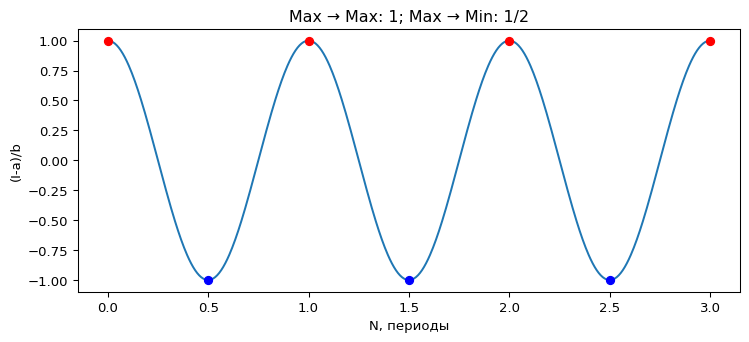

In [2]:
N=np.linspace(0,3,601)
fig,ax=plt.subplots(); ax.plot(N,np.cos(2*np.pi*N))
for k in np.arange(0,3.01,.5):
    ax.plot(k,np.cos(2*np.pi*k),'ro' if k%1==0 else 'bo')
ax.set(xlabel='N, периоды',ylabel='(I-a)/b',title='Max → Max: 1; Max → Min: 1/2')
plt.show()

## 2. Нумерация как система ограничений на графе

Узлы — фрагменты полос. Ребро сообщает $N_j-N_i=d_{ij}$: например, 1 для соседних
максимумов. Из-за отсутствия абсолютного номера один узел фиксируют: N₀=0.
Сумма d по любому замкнутому циклу должна быть нулём. Ненулевая сумма — признак
противоречивого сопоставления или пропущенной полосы.

Если граф имеет несколько компонент, каждая имеет собственную неизвестную
константу. Нельзя восстановить их относительный целый порядок простой сортировкой.
С шумными ограничениями можно решать взвешенный МНК по графу, но затем проверить
целочисленность и топологическую согласованность; усреднённый дробный номер
не всегда физически допустим.

In [3]:
edges=[(0,1,1.),(1,2,1.),(2,3,1.),(0,3,3.)]
A=[]; rhs=[]
for i,j,d in edges:
    row=np.zeros(4); row[j]=1; row[i]=-1
    A.append(row); rhs.append(d)
A.append([1,0,0,0]); rhs.append(0)
A=np.array(A); rhs=np.array(rhs)
numbers=np.linalg.lstsq(A,rhs,rcond=None)[0]
print('Согласованные номера:',numbers,'невязка:',np.linalg.norm(A@numbers-rhs))
bad=rhs.copy(); bad[3]=4
bad_numbers=np.linalg.lstsq(A,bad,rcond=None)[0]
print('Противоречивые ограничения:',bad_numbers,'невязка:',np.linalg.norm(A@bad_numbers-bad))
assert np.linalg.norm(A@bad_numbers-bad)>.1

Согласованные номера: [-0.  1.  2.  3.] невязка: 1.7039322240558702e-15
Противоречивые ограничения: [-0.    1.25  2.5   3.75] невязка: 0.5


## 3. От контуров к плотной карте

На каждой строке известны пересечения $(x_i,N_i)$. Нужно найти N(x) между ними.
Линейная интерполяция непрерывна, но производная скачет в узлах. Кубический сплайн
на каждом интервале имеет вид $S_i=a_i+b_i t+c_i t^2+d_i t^3$ и согласует значения,
первые и вторые производные в соседних интервалах.

Для натурального сплайна задаются $S''(x_0)=S''(x_n)=0$.
Если $M_i=S''(x_i)$ и $h_i=x_{i+1}-x_i$, внутренние уравнения:
$$h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}
=6\left(\frac{N_{i+1}-N_i}{h_i}-\frac{N_i-N_{i-1}}{h_{i-1}}\right).$$
Получается трёхдиагональная линейная система. Граничные условия — предположение
о функции, а не следствие данных. Натуральный сплайн не обязан точно воспроизводить
квадратичную функцию у границ.

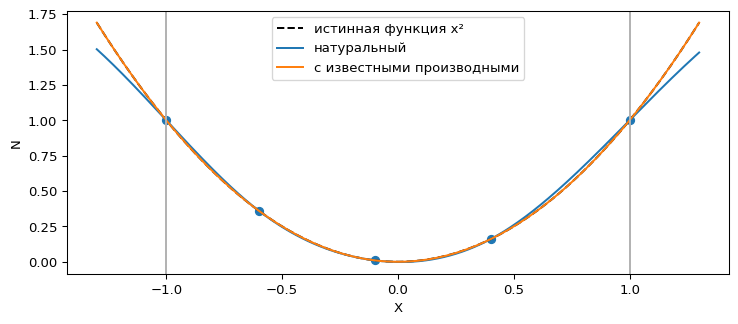

Граничная вторая производная натурального: 0.0 3.1086244689504383e-15


In [4]:
nodes=np.array([-1.,-.6,-.1,.4,1.])
values=nodes**2
natural=interpolate.CubicSpline(nodes,values,bc_type='natural')
clamped=interpolate.CubicSpline(nodes,values,bc_type=((1,-2.),(1,2.)))
x=np.linspace(-1.3,1.3,400)
fig,ax=plt.subplots(); ax.plot(x,x*x,'k--',label='истинная функция x²')
ax.plot(x,natural(x),label='натуральный'); ax.plot(x,clamped(x),label='с известными производными')
ax.scatter(nodes,values); ax.axvline(-1,color='0.7'); ax.axvline(1,color='0.7')
ax.legend(); ax.set(xlabel='X',ylabel='N'); plt.show()
print('Граничная вторая производная натурального:',natural(-1,2),natural(1,2))

## 4. Принципиальная потеря информации между полосами

Если оставить только линии N=k, функции $N$ и
$\widetilde N=N+\varepsilon\sin(2\pi N)$ имеют **те же значения на всех целых
контурах**, но различаются между ними. Для достаточно малого ε преобразование
остаётся монотонным. По одним контурам выбрать между ними невозможно.
Исходные полутоновые изображения различаются; трассировка эту информацию отбросила.

Поэтому сплайн — восстановление при допущении гладкости, а не универсальное
извлечение всей доступной фазы. Экстраполяция за последний контур ещё сильнее
зависит от допущений. В программе синтетически продлённые полосы нужно отличать от измеренных.

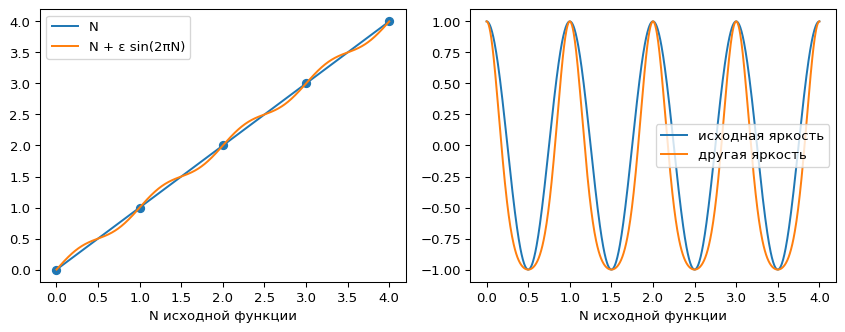

In [5]:
N=np.linspace(0,4,800)
epsilon=.08
alternative=N+epsilon*np.sin(2*np.pi*N)
assert np.min(1+epsilon*2*np.pi*np.cos(2*np.pi*N))>0
fig,axes=plt.subplots(1,2)
axes[0].plot(N,N,label='N'); axes[0].plot(N,alternative,label='N + ε sin(2πN)')
axes[0].scatter(np.arange(5),np.arange(5)); axes[0].legend()
axes[1].plot(N,np.cos(2*np.pi*N),label='исходная яркость')
axes[1].plot(N,np.cos(2*np.pi*alternative),label='другая яркость'); axes[1].legend()
for ax in axes: ax.set_xlabel('N исходной функции')
plt.tight_layout(); plt.show()

## Задания

1. Что произойдёт со всей картой, если в режиме Max+Min дать каждому соседу шаг 1?
2. Почему увеличение числа отсчётов на нарисованной линии не добавляет новых порядков фазы?
3. Измените последние значения узлов и сравните экстраполяцию разных сплайнов.
4. Как определить, что граф нумерации содержит две несвязанные компоненты?

<details><summary>Разбор</summary>

1. Фаза растянется примерно вдвое. 2. Это более подробное положение одного уровня,
а не измерение промежуточных значений N. 3. Вне данных поведение определяется
условиями на производные и выбранной моделью. 4. Обходом графа; для каждой компоненты
нужен отдельный отсчёт, и относительный порядок без дополнительной информации неизвестен.
</details>

**Чтение:** [SciPy CubicSpline](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html).
В DigitQt граничная экстраполяция сплайна линейна по касательной; стандартное
продолжение `CubicSpline` вне интервала кубическое. Не смешивайте эти политики.
Далее: [метод Фурье](05_fourier.ipynb).